In [2]:
import os
import pandas as pd

In [ ]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split

device = torch.device("mps")
root = os.path.expanduser("~/Documents/Code/fruit_project/data/resized")
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.3, 0.3, 0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([              # center-crop version we settled on
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

full_train = datasets.ImageFolder(root, transform=train_tf)
full_eval = datasets.ImageFolder(root, transform=eval_tf)
targets = full_train.targets
classes = full_train.classes

idx = list(range(len(targets)))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=targets, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50,
                                     stratify=[targets[i] for i in temp_idx], random_state=42)

train_ds = Subset(full_train, train_idx)
val_ds = Subset(full_eval, val_idx)
test_ds = Subset(full_eval, test_idx)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)

# rebuild the ResNet and load the saved weights (weights=None skips the pretrained download)
resnet = models.resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, len(classes))
resnet.load_state_dict(torch.load("resnet18_fruit.pt", map_location=device))
resnet = resnet.to(device).eval()

# sanity check
correct = n = 0
with torch.no_grad():
    for X, y in test_loader:
        correct += (resnet(X.to(device)).argmax(1).cpu() == y).sum().item()
        n += len(y)
print("test acc:", correct / n)

test acc: 0.9604166666666667


In [ ]:
from collections import Counter
root = os.path.expanduser('../dataset')
xt = (".jpeg", ".jpg", ".png") # extensions

for dirpath, dirs, files in sorted(os.walk(root)):
    images = [f for f in files if f.lower().endswith(xt)]
    if images:
        print(f"{os.path.relpath(dirpath, root)}: {len(images)} images")
        print("   extensions:", dict(Counter(os.path.splitext(f)[1].lower() for f in images)))

FreshApple: 200 images
   extensions: {'.jpg': 200}
FreshBanana: 200 images
   extensions: {'.jpg': 200}
FreshGrape: 200 images
   extensions: {'.jpg': 200}
FreshGuava: 200 images
   extensions: {'.jpg': 200}
FreshJujube: 200 images
   extensions: {'.jpg': 200}
FreshOrange: 200 images
   extensions: {'.jpg': 200}
FreshPomegranate: 200 images
   extensions: {'.jpg': 200}
FreshStrawberry: 200 images
   extensions: {'.jpg': 200}
RottenApple: 200 images
   extensions: {'.jpg': 200}
RottenBanana: 200 images
   extensions: {'.jpg': 200}
RottenGrape: 200 images
   extensions: {'.jpg': 200}
RottenGuava: 200 images
   extensions: {'.jpg': 200}
RottenJujube: 200 images
   extensions: {'.jpg': 200}
RottenOrange: 200 images
   extensions: {'.jpg': 200}
RottenPomegranate: 200 images
   extensions: {'.jpg': 200}
RottenStrawberry: 200 images
   extensions: {'.jpg': 200}


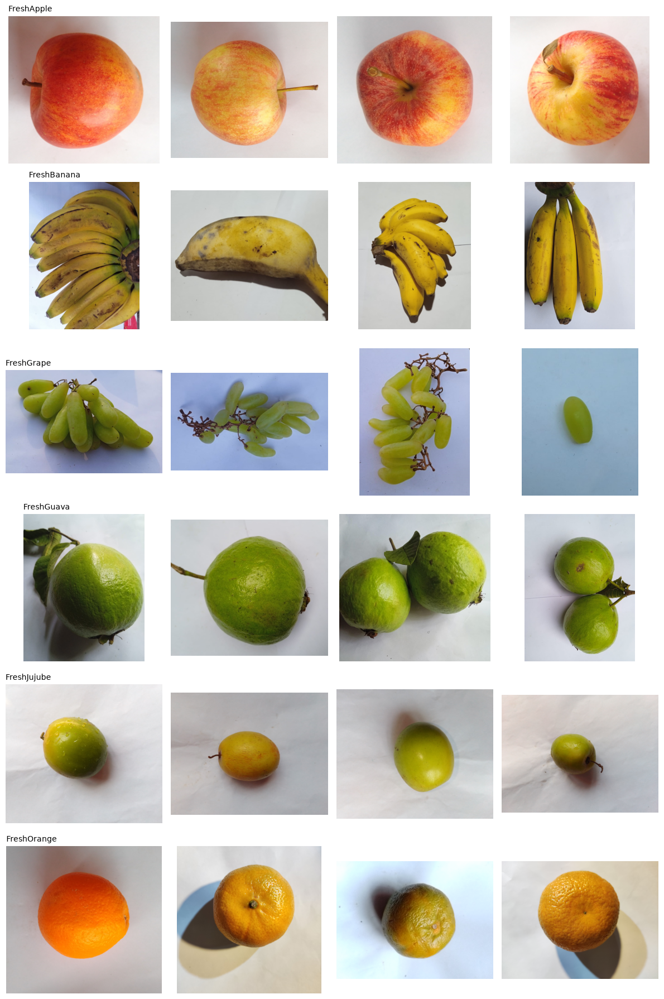

In [4]:
import random
import matplotlib.pyplot as plt
from PIL import Image

class_dirs = sorted(
    dp for dp, _, fs in os.walk(root)
    if any(f.lower().endswith(xt) for f in fs)
)[:6]

fig, axes = plt.subplots(len(class_dirs), 4, figsize = (12, 3*len(class_dirs)))
axes = axes.reshape(len(class_dirs), 4)

for row, d in enumerate(class_dirs):
    files = [f for f in os.listdir(d) if f.lower().endswith(xt)]
    for col, f in enumerate(random.sample(files, min(4, len(files)))):
        axes[row, col].imshow(Image.open(os.path.join(d, f)))
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(os.path.basename(d), loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [5]:
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

device = torch.device("mps")
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats, also used for transfer learning later

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.3, 0.3, 0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# same folder loaded twice: one version with augmentation (train), one without (val/test)
full_train = datasets.ImageFolder(root, transform=train_tf)
full_eval = datasets.ImageFolder(root, transform=eval_tf)
targets = full_train.targets

# stratified 70 / 15 / 15 split, so every class appears equally in each part
idx = list(range(len(targets)))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=targets, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50,
                                     stratify=[targets[i] for i in temp_idx], random_state=42)

train_ds = Subset(full_train, train_idx)
val_ds = Subset(full_eval, val_idx)
test_ds = Subset(full_eval, test_idx)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)

print("classes:", full_train.classes)
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")
X, y = next(iter(train_loader))
print(X.shape, y[:8])      # expect torch.Size([32, 3, 224, 224])

classes: ['FreshApple', 'FreshBanana', 'FreshGrape', 'FreshGuava', 'FreshJujube', 'FreshOrange', 'FreshPomegranate', 'FreshStrawberry', 'RottenApple', 'RottenBanana', 'RottenGrape', 'RottenGuava', 'RottenJujube', 'RottenOrange', 'RottenPomegranate', 'RottenStrawberry']
train 2240 | val 480 | test 480
torch.Size([32, 3, 224, 224]) tensor([ 2, 11,  4,  1,  1, 14,  9, 14])


In [11]:
import torch.nn as nn
import time

class BaselineCNN(nn.Module):
    def __init__(self, num_classes=16):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * X.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += X.size(0)
    return total_loss / n, correct / n


def fit(model, epochs, lr, name):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best, history = 0.0, []
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        history.append((tl, ta, vl, va))
        if va > best:
            best = va
            torch.save(model.state_dict(), f"{name}.pt")
        print(f"Epoch {ep:2d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    print(f"best val acc: {best:.3f}")
    return history


model = BaselineCNN().to(device)
history = fit(model, epochs=15, lr=1e-3, name="baseline_cnn")

Epoch  1/15 | train loss 1.878 acc 0.404 | val loss 1.451 acc 0.604 | 100s
Epoch  2/15 | train loss 1.422 acc 0.559 | val loss 1.166 acc 0.660 | 95s
Epoch  3/15 | train loss 1.212 acc 0.613 | val loss 1.178 acc 0.625 | 93s
Epoch  4/15 | train loss 1.080 acc 0.650 | val loss 1.008 acc 0.717 | 91s
Epoch  5/15 | train loss 0.997 acc 0.675 | val loss 0.848 acc 0.758 | 92s
Epoch  6/15 | train loss 0.932 acc 0.700 | val loss 0.841 acc 0.742 | 94s
Epoch  7/15 | train loss 0.861 acc 0.730 | val loss 0.825 acc 0.702 | 97s
Epoch  8/15 | train loss 0.828 acc 0.736 | val loss 0.718 acc 0.790 | 93s
Epoch  9/15 | train loss 0.825 acc 0.724 | val loss 0.677 acc 0.798 | 94s
Epoch 10/15 | train loss 0.758 acc 0.750 | val loss 0.773 acc 0.742 | 97s
Epoch 11/15 | train loss 0.690 acc 0.771 | val loss 0.619 acc 0.833 | 94s
Epoch 12/15 | train loss 0.691 acc 0.787 | val loss 0.593 acc 0.785 | 93s
Epoch 13/15 | train loss 0.667 acc 0.788 | val loss 0.609 acc 0.812 | 93s
Epoch 14/15 | train loss 0.622 acc 0.

In [12]:
src = root                                             
dst = os.path.expanduser("~/Documents/Code/fruit_project/data/resized")

for dirpath, dirs, files in os.walk(src):
    for f in files:
        if f.lower().endswith(xt):
            out_dir = os.path.join(dst, os.path.relpath(dirpath, src))
            os.makedirs(out_dir, exist_ok=True)
            out_path = os.path.join(out_dir, f)
            if not os.path.exists(out_path):
                img = Image.open(os.path.join(dirpath, f)).convert("RGB")
                img = transforms.Resize(256)(img)      
                img.save(out_path, quality=95)
print("done")

done


In [13]:
root = os.path.expanduser("~/Documents/Code/fruit_project/data/resized")

In [14]:
from torchvision import models

resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, 16)        
resnet = resnet.to(device)

history_resnet = fit(resnet, epochs=8, lr=3e-4, name="resnet18_fruit")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/kushbajpai/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


Epoch  1/8 | train loss 0.451 acc 0.876 | val loss 0.172 acc 0.942 | 111s
Epoch  2/8 | train loss 0.122 acc 0.962 | val loss 0.263 acc 0.919 | 102s
Epoch  3/8 | train loss 0.088 acc 0.977 | val loss 0.106 acc 0.971 | 100s
Epoch  4/8 | train loss 0.094 acc 0.971 | val loss 0.184 acc 0.948 | 99s
Epoch  5/8 | train loss 0.060 acc 0.984 | val loss 0.184 acc 0.958 | 98s
Epoch  6/8 | train loss 0.066 acc 0.979 | val loss 0.154 acc 0.944 | 99s
Epoch  7/8 | train loss 0.051 acc 0.983 | val loss 0.095 acc 0.965 | 98s
Epoch  8/8 | train loss 0.059 acc 0.981 | val loss 0.097 acc 0.967 | 99s
best val acc: 0.971


test accuracy: 0.960

                   precision    recall  f1-score   support

       FreshApple      0.968     1.000     0.984        30
      FreshBanana      1.000     1.000     1.000        30
       FreshGrape      0.938     1.000     0.968        30
       FreshGuava      1.000     1.000     1.000        30
      FreshJujube      1.000     1.000     1.000        30
      FreshOrange      1.000     0.967     0.983        30
 FreshPomegranate      1.000     0.867     0.929        30
  FreshStrawberry      0.968     1.000     0.984        30
      RottenApple      0.962     0.833     0.893        30
     RottenBanana      1.000     1.000     1.000        30
      RottenGrape      1.000     0.933     0.966        30
      RottenGuava      1.000     0.967     0.983        30
     RottenJujube      0.882     1.000     0.938        30
     RottenOrange      1.000     0.833     0.909        30
RottenPomegranate      0.750     1.000     0.857        30
 RottenStrawberry      1.000     

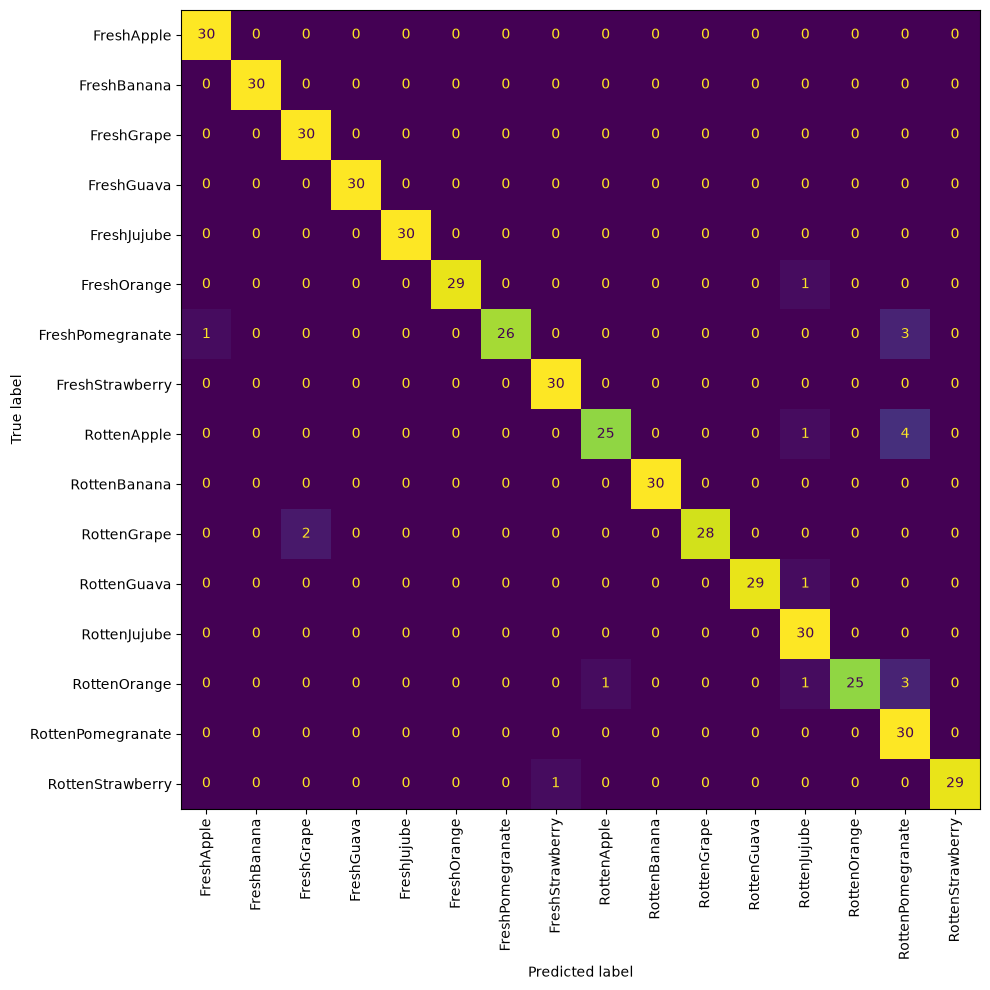

fresh/rotten accuracy (ignoring fruit type): 0.9854166666666667
rotten predicted as fresh: 3 of 240
fresh predicted as rotten: 4 of 240


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

resnet.load_state_dict(torch.load("resnet18_fruit.pt", map_location=device))   # best-val weights
resnet.eval()

all_preds, all_true = [], []
with torch.no_grad():
    for X, y in test_loader:
        preds = resnet(X.to(device)).argmax(1).cpu()
        all_preds.append(preds)
        all_true.append(y)
all_preds = torch.cat(all_preds).numpy()
all_true = torch.cat(all_true).numpy()

classes = full_train.classes
print(f"test accuracy: {(all_preds == all_true).mean():.3f}\n")
print(classification_report(all_true, all_preds, target_names=classes, digits=3))

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(confusion_matrix(all_true, all_preds), display_labels=classes).plot(
    ax=ax, xticks_rotation=90, colorbar=False)
plt.tight_layout()
plt.show()

# the error that matters most for quality grading: rotten fruit called fresh
is_fresh_true = np.array([classes[i].startswith("Fresh") for i in all_true])
is_fresh_pred = np.array([classes[i].startswith("Fresh") for i in all_preds])
print("fresh/rotten accuracy (ignoring fruit type):", (is_fresh_true == is_fresh_pred).mean())
print("rotten predicted as fresh:", (~is_fresh_true & is_fresh_pred).sum(), "of", (~is_fresh_true).sum())
print("fresh predicted as rotten:", (is_fresh_true & ~is_fresh_pred).sum(), "of", is_fresh_true.sum())

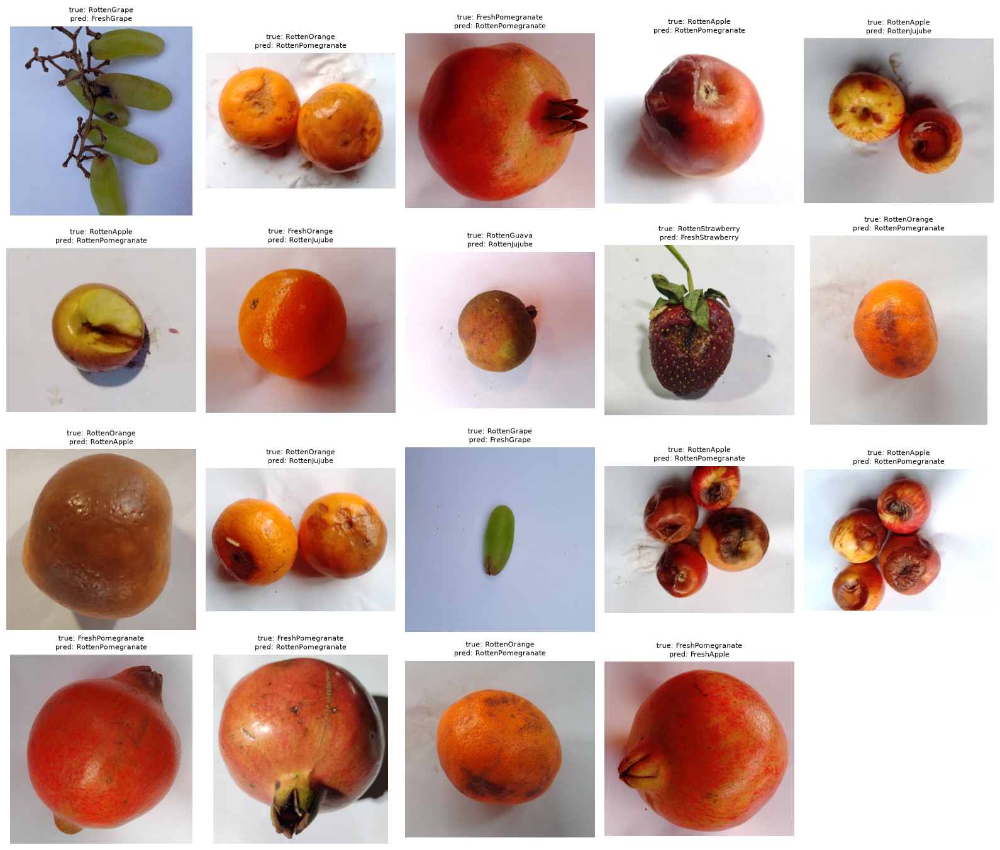

In [16]:
wrong = np.where(all_preds != all_true)[0]
cols = 5
rows = int(np.ceil(len(wrong) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.4 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong):
    path = full_eval.samples[test_idx[i]][0]
    ax.imshow(Image.open(path))
    ax.set_title(f"true: {classes[all_true[i]]}\npred: {classes[all_preds[i]]}", fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
model.load_state_dict(torch.load("baseline_cnn.pt", map_location=device))
loss, acc = run_epoch(model, test_loader, nn.CrossEntropyLoss())
print(f"baseline test acc: {acc:.3f}")

baseline test acc: 0.833


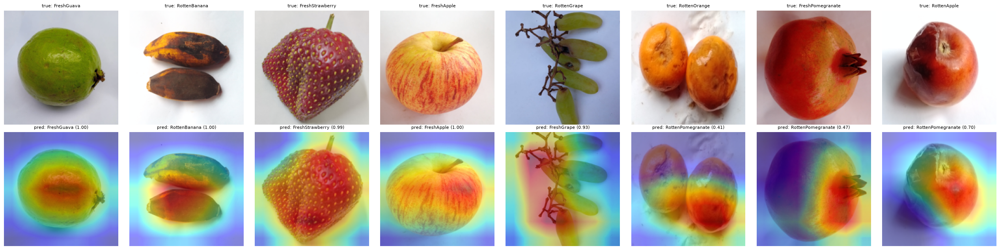

In [19]:
import torch.nn.functional as F

def grad_cam(model, x, target_layer):
    acts, grads = {}, {}
    def fwd_hook(m, i, o):
        acts["a"] = o
        o.register_hook(lambda g: grads.update(g=g))
    h = target_layer.register_forward_hook(fwd_hook)
    model.eval()
    out = model(x)
    pred = out.argmax(1).item()
    model.zero_grad()
    out[0, pred].backward()
    h.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)            # importance of each channel
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))       # weighted sum of feature maps
    cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, pred, out.softmax(1)[0, pred].item()

def show_cam(indices):
    fig, axes = plt.subplots(2, len(indices), figsize=(3.2 * len(indices), 6.4))
    for col, i in enumerate(indices):
        x, y = test_ds[i]
        cam, pred, conf = grad_cam(resnet, x.unsqueeze(0).to(device), resnet.layer4)
        img = (x.permute(1, 2, 0).numpy() * np.array(std) + np.array(mean)).clip(0, 1)
        heat = plt.cm.jet(cam)[..., :3]
        axes[0, col].imshow(img)
        axes[0, col].set_title(f"true: {classes[y]}", fontsize=8)
        axes[1, col].imshow(0.55 * img + 0.45 * heat)
        axes[1, col].set_title(f"pred: {classes[pred]} ({conf:.2f})", fontsize=8)
        axes[0, col].axis("off")
        axes[1, col].axis("off")
    plt.tight_layout()
    plt.show()

right = np.where(all_preds == all_true)[0]
wrong = np.where(all_preds != all_true)[0]
show_cam(list(np.random.choice(right, 4, replace=False)) + list(wrong[:4]))

9 photos | own-photo accuracy: 0.111
  FreshApple: 0.00 (3 photos)
  FreshBanana: 1.00 (1 photos)
  FreshPomegranate: 0.00 (5 photos)
fresh/rotten correct: 0.111
8 mistakes


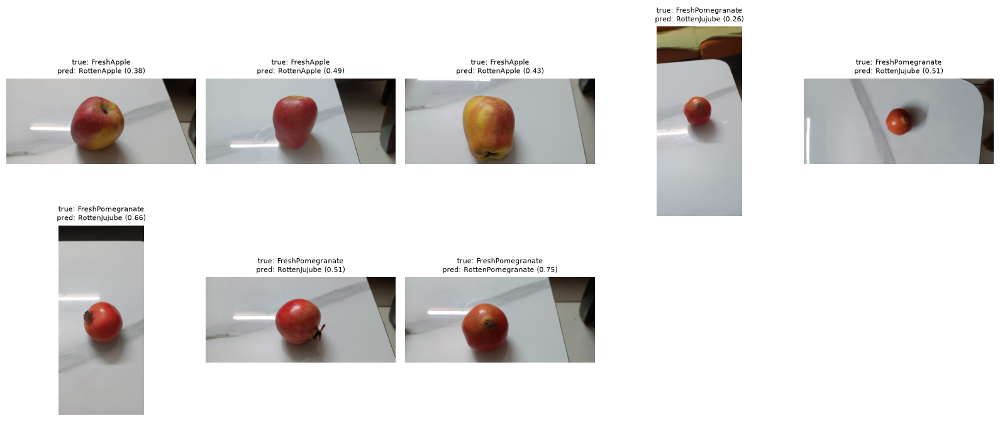

In [21]:
from PIL import Image, ImageOps

own_root = os.path.expanduser("~/Documents/Code/fruit_project/data/own_photos")

resnet.eval()
results = []

for cname in sorted(os.listdir(own_root)):
    d = f"{own_root}/{cname}"
    if not os.path.isdir(d):
        continue
    if cname not in classes:
        print("skipping folder with unknown name:", cname)
        continue
    for f in sorted(os.listdir(d)):
        if f.lower().endswith(".heic"):
            print("can't read HEIC, convert to JPG first:", f)
            continue
        if not f.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        img = ImageOps.exif_transpose(Image.open(f"{d}/{f}")).convert("RGB")   # fixes sideways phone photos
        x = eval_tf(img).unsqueeze(0).to(device)
        with torch.no_grad():
            probs = resnet(x).softmax(1)[0].cpu()
        pred = probs.argmax().item()
        results.append((f"{d}/{f}", classes.index(cname), pred, probs[pred].item()))

true = np.array([r[1] for r in results])
pred = np.array([r[2] for r in results])
print(f"{len(results)} photos | own-photo accuracy: {(true == pred).mean():.3f}")
for c in sorted(set(true)):
    m = true == c
    print(f"  {classes[c]}: {(pred[m] == c).mean():.2f} ({m.sum()} photos)")
fr_ok = np.mean([classes[t].startswith("Fresh") == classes[p].startswith("Fresh")
                 for t, p in zip(true, pred)])
print("fresh/rotten correct:", round(fr_ok, 3))

bad = [r for r in results if r[1] != r[2]]
print(len(bad), "mistakes")
if bad:
    cols = 5
    rows = int(np.ceil(len(bad) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.4 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (path, t, p, conf) in zip(axes.flat, bad):
        ax.imshow(ImageOps.exif_transpose(Image.open(path)).convert("RGB"))
        ax.set_title(f"true: {classes[t]}\npred: {classes[p]} ({conf:.2f})", fontsize=8)
    plt.tight_layout()
    plt.show()

control (dataset photos, same code): 38/40

WhatsApp Image 2026-11-03 at 8.02.28 PM (2).jpeg [1152x520] true=FreshApple -> RottenApple 0.38, RottenJujube 0.23, FreshApple 0.21
WhatsApp Image 2026-11-03 at 8.02.29 PM (1).jpeg [1152x520] true=FreshApple -> RottenApple 0.49, FreshApple 0.38, RottenPomegranate 0.06
WhatsApp Image 2026-11-03 at 8.02.29 PM.jpeg [1152x520] true=FreshApple -> RottenApple 0.43, FreshApple 0.37, RottenPomegranate 0.09
WhatsApp Image 2026-11-03 at 8.02.29 PM (2).jpeg [520x1152] true=FreshBanana -> FreshBanana 0.57, RottenBanana 0.39, RottenGrape 0.01
WhatsApp Image 2026-11-03 at 8.02.27 PM (1).jpeg [520x1152] true=FreshPomegranate -> RottenJujube 0.26, FreshOrange 0.20, FreshBanana 0.11
WhatsApp Image 2026-11-03 at 8.02.27 PM (2).jpeg [1152x520] true=FreshPomegranate -> RottenJujube 0.51, RottenPomegranate 0.18, RottenGrape 0.09
WhatsApp Image 2026-11-03 at 8.02.27 PM.jpeg [520x1152] true=FreshPomegranate -> RottenJujube 0.66, RottenPomegranate 0.11, FreshJujube 

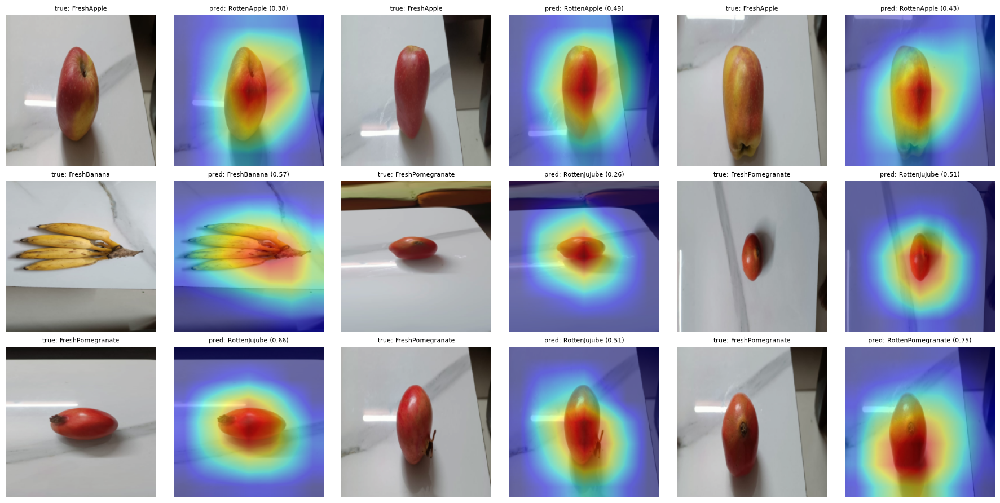

In [22]:
def predict_pil(img):
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        return resnet(x).softmax(1)[0].cpu()

# 1. CONTROL: dataset test photos through the exact same code path as your photos.
#    If this is ~95%+, the photo-loading code is fine and the gap is real.
ctrl = random.sample(list(test_idx), 40)
ok = 0
for i in ctrl:
    path, label = full_eval.samples[i]
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    ok += int(predict_pil(img).argmax().item() == label)
print(f"control (dataset photos, same code): {ok}/{len(ctrl)}\n")

# 2. Top-3 guesses for each of your photos
for path, t, p, conf in results:
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    probs = predict_pil(img)
    top = probs.topk(3)
    guesses = ", ".join(f"{classes[i]} {v:.2f}" for v, i in zip(top.values, top.indices))
    print(f"{os.path.basename(path)} [{img.size[0]}x{img.size[1]}] true={classes[t]} -> {guesses}")

# 3. What the model sees (224x224 squashed input) and where it looks
n = len(results)
rows = int(np.ceil(n / 3))
fig, axes = plt.subplots(rows, 6, figsize=(18, 3 * rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for k, (path, t, p, conf) in enumerate(results):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    cam, pred_i, c = grad_cam(resnet, x, resnet.layer4)
    shown = (x[0].cpu().permute(1, 2, 0).numpy() * np.array(std) + np.array(mean)).clip(0, 1)
    r, col = divmod(k, 3)
    axes[r, col * 2].imshow(shown)
    axes[r, col * 2].set_title(f"true: {classes[t]}", fontsize=8)
    axes[r, col * 2 + 1].imshow(0.55 * shown + 0.45 * plt.cm.jet(cam)[..., :3])
    axes[r, col * 2 + 1].set_title(f"pred: {classes[pred_i]} ({c:.2f})", fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
def to_square(img, mode):
    w, h = img.size
    if mode == "crop":
        s = min(w, h)
        l, t = (w - s) // 2, (h - s) // 2
        return img.crop((l, t, l + s, t + s))
    if mode == "pad":
        s = max(w, h)
        canvas = Image.new("RGB", (s, s), (124, 116, 104))      # ImageNet mean color
        canvas.paste(img, ((s - w) // 2, (s - h) // 2))
        return canvas
    return img      # "squash" = current behavior

def predict_mode(img, mode):
    x = eval_tf(to_square(img, mode)).unsqueeze(0).to(device)
    with torch.no_grad():
        return resnet(x).softmax(1)[0].cpu()

for mode in ["squash", "crop", "pad"]:
    exact = fr = 0
    for path, t, _, _ in results:
        img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
        p = predict_mode(img, mode).argmax().item()
        exact += int(p == t)
        fr += int(classes[p].startswith("Fresh") == classes[t].startswith("Fresh"))
    ctrl_ok = 0
    for i in ctrl:
        path, label = full_eval.samples[i]
        img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
        ctrl_ok += int(predict_mode(img, mode).argmax().item() == label)
    print(f"{mode:7s} | own photos exact {exact}/9, fresh-vs-rotten {fr}/9 | dataset control {ctrl_ok}/{len(ctrl)}")

squash  | own photos exact 1/9, fresh-vs-rotten 1/9 | dataset control 38/40
crop    | own photos exact 3/9, fresh-vs-rotten 3/9 | dataset control 39/40
pad     | own photos exact 1/9, fresh-vs-rotten 1/9 | dataset control 38/40


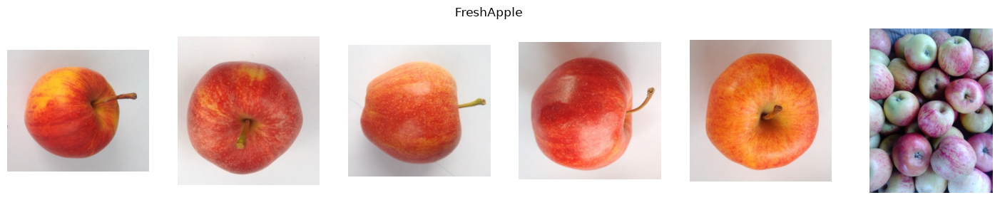

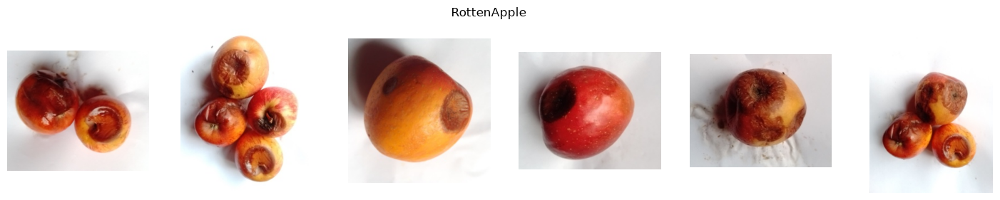

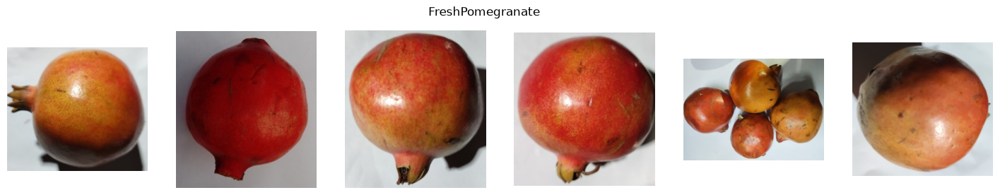

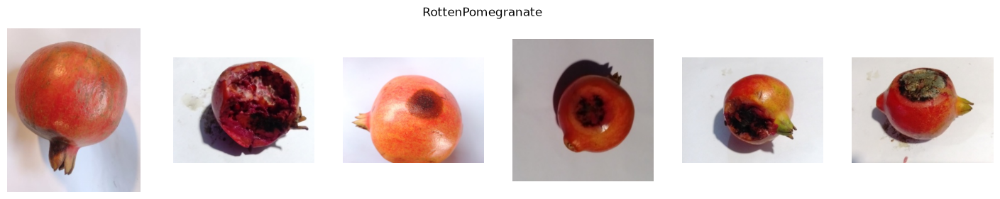

In [2]:
def show_class(cname, n=6):
    paths = [p for p, l in full_eval.samples if classes[l] == cname]
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    for ax, p in zip(axes, random.sample(paths, n)):
        ax.imshow(Image.open(p))
        ax.axis("off")
    fig.suptitle(cname)
    plt.show()

for c in ["FreshApple", "RottenApple", "FreshPomegranate", "RottenPomegranate"]:
    show_class(c)

In [4]:
own_root = os.path.expanduser("~/Documents/Code/fruit_project/data/own_photos")
own = []   # (path, true class index)
for cname in sorted(os.listdir(own_root)):
    d = f"{own_root}/{cname}"
    if os.path.isdir(d) and cname in classes:
        for f in sorted(os.listdir(d)):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                own.append((f"{d}/{f}", classes.index(cname)))
print(len(own), "photos")

def center_zoom(img, frac):
    w, h = img.size
    s = int(min(w, h) * frac)
    l, t = (w - s) // 2, (h - s) // 2
    return img.crop((l, t, l + s, t + s))

def predict(img):
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        return resnet(x).softmax(1)[0].cpu()

for frac in [1.0, 0.7, 0.5, 0.35]:
    exact = fresh_ok = 0
    for path, t in own:
        img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
        p = predict(center_zoom(img, frac)).argmax().item()
        exact += int(p == t)
        fresh_ok += int(classes[p].startswith("Fresh") == classes[t].startswith("Fresh"))
    print(f"central {int(frac * 100):3d}% of the short side | exact {exact}/{len(own)} | fresh-vs-rotten {fresh_ok}/{len(own)}")

9 photos
central 100% of the short side | exact 3/9 | fresh-vs-rotten 3/9
central  70% of the short side | exact 3/9 | fresh-vs-rotten 3/9
central  50% of the short side | exact 3/9 | fresh-vs-rotten 4/9
central  35% of the short side | exact 4/9 | fresh-vs-rotten 6/9
